In [1]:
!pip install pandas numpy matplotlib seaborn plotly scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

In [3]:
!pip install requests pandas


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import requests

url = "https://bulks-faostat.fao.org/production/Production_Crops_Livestock_E_All_Data_(Normalized).zip"

response = requests.get(url, stream=True)

with open("FAOSTAT_Production.zip", "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)

print("Download completed!")

Download completed!


In [5]:
import zipfile

with zipfile.ZipFile("FAOSTAT_Production.zip", "r") as zip_ref:
    zip_ref.extractall("FAOSTAT_Production")

print("Dataset extracted!")

Dataset extracted!


In [6]:
import os

os.listdir("FAOSTAT_Production")

['Production_Crops_Livestock_E_All_Data_(Normalized).csv',
 'Production_Crops_Livestock_E_AreaCodes.csv',
 'Production_Crops_Livestock_E_Elements.csv',
 'Production_Crops_Livestock_E_Flags.csv',
 'Production_Crops_Livestock_E_ItemCodes.csv']

In [7]:
df = pd.read_csv(
    "FAOSTAT_Production/Production_Crops_Livestock_E_All_Data_(Normalized).csv",
    encoding="latin1"
)

df.head()

C:\Users\user\AppData\Local\Temp\ipykernel_24780\2146355136.py:1: DtypeWarning: Columns (0: Note) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Year Code,Year,Unit,Value,Flag,Note
0,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,1961,1961,ha,0.0,A,NaN
1,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,1962,1962,ha,0.0,A,NaN
2,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,1963,1963,ha,0.0,A,NaN
3,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,1964,1964,ha,0.0,A,NaN
4,2,'004,Afghanistan,221,'01371,"Almonds, in shell",5312,Area harvested,1965,1965,ha,0.0,A,NaN


In [8]:
print(df.shape)

(4209110, 14)


In [9]:
df.columns

Index(['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)',
       'Item', 'Element Code', 'Element', 'Year Code', 'Year', 'Unit', 'Value',
       'Flag', 'Note'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4209110 entries, 0 to 4209109
Data columns (total 14 columns):
 #   Column           Dtype  
---  ------           -----  
 0   Area Code        int64  
 1   Area Code (M49)  str    
 2   Area             str    
 3   Item Code        int64  
 4   Item Code (CPC)  str    
 5   Item             str    
 6   Element Code     int64  
 7   Element          str    
 8   Year Code        int64  
 9   Year             int64  
 10  Unit             str    
 11  Value            float64
 12  Flag             str    
 13  Note             str    
dtypes: float64(1), int64(5), str(8)
memory usage: 449.6 MB


In [11]:
df["Area"].unique()[:20]

<StringArray>
[        'Afghanistan',             'Albania',             'Algeria',
              'Angola', 'Antigua and Barbuda',           'Argentina',
             'Armenia',           'Australia',             'Austria',
          'Azerbaijan',             'Bahamas',             'Bahrain',
          'Bangladesh',            'Barbados',             'Belarus',
             'Belgium',  'Belgium-Luxembourg',              'Belize',
               'Benin',              'Bhutan']
Length: 20, dtype: str

In [12]:
df["Item"].unique()[:30]

<StringArray>
[                                                        'Almonds, in shell',
 'Anise, badian, coriander, cumin, caraway, fennel and juniper berries, raw',
                                                                    'Apples',
                                                                  'Apricots',
                                                                     'Asses',
                                                                    'Barley',
                                                                'Beans, dry',
                                             'Butter and ghee of sheep milk',
                                                        'Butter of cow milk',
                                                           'Buttermilk, dry',
                                                                    'Camels',
                                              'Cantaloupes and other melons',
                                                  

In [13]:
nigeria = df[df["Area"] == "Nigeria"].copy()

print(nigeria.shape)

(17539, 14)


In [14]:
nigeria.head()

,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Year Code,Year,Unit,Value,Flag,Note
2068272,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1961,1961,An,1398000.0,E,NaN
2068273,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1962,1962,An,1364000.0,E,NaN
2068274,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1963,1963,An,1330000.0,E,NaN
2068275,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1964,1964,An,1296000.0,A,NaN
2068276,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1965,1965,An,1240000.0,A,NaN


In [15]:
nigeria.info()

<class 'pandas.DataFrame'>
RangeIndex: 17539 entries, 2068272 to 2085810
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area Code        17539 non-null  int64  
 1   Area Code (M49)  17539 non-null  str    
 2   Area             17539 non-null  str    
 3   Item Code        17539 non-null  int64  
 4   Item Code (CPC)  17539 non-null  str    
 5   Item             17539 non-null  str    
 6   Element Code     17539 non-null  int64  
 7   Element          17539 non-null  str    
 8   Year Code        17539 non-null  int64  
 9   Year             17539 non-null  int64  
 10  Unit             17539 non-null  str    
 11  Value            17254 non-null  float64
 12  Flag             17539 non-null  str    
 13  Note             439 non-null    str    
dtypes: float64(1), int64(5), str(8)
memory usage: 1.9 MB


In [16]:
nigeria.isnull().sum()

Area Code              0
Area Code (M49)        0
Area                   0
Item Code              0
Item Code (CPC)        0
Item                   0
Element Code           0
Element                0
Year Code              0
Year                   0
Unit                   0
Value                285
Flag                   0
Note               17100
dtype: int64

In [17]:
nigeria.describe()

,Area Code,Item Code,Element Code,Year Code,Year,Value
count,17539.0,17539.000000,17539.000000,17539.000000,17539.000000,1.725400e+04
mean,159.0,954.376874,5406.022008,1992.870688,1992.870688,2.088480e+06
std,0.0,1835.089920,104.028976,18.449851,18.449851,8.047008e+06
min,159.0,15.000000,5111.000000,1961.000000,1961.000000,0.000000e+00
25%,159.0,254.000000,5312.000000,1977.000000,1977.000000,4.096650e+03
50%,159.0,661.000000,5412.000000,1993.000000,1993.000000,8.000000e+04
75%,159.0,1057.000000,5510.000000,2009.000000,2009.000000,7.750096e+05
max,159.0,17530.000000,5513.000000,2024.000000,2024.000000,1.431072e+08


In [18]:
nigeria.columns

Index(['Area Code', 'Area Code (M49)', 'Area', 'Item Code', 'Item Code (CPC)',
       'Item', 'Element Code', 'Element', 'Year Code', 'Year', 'Unit', 'Value',
       'Flag', 'Note'],
      dtype='str')

In [19]:
nigeria["Element"].value_counts()

Element
Production                       6700
Area harvested                   3818
Yield                            3757
Producing Animals/Slaughtered    1216
Yield/Carcass Weight              960
Stocks                            832
Laying                            128
Milk Animals                      128
Name: count, dtype: int64

In [20]:
nigeria["Unit"].value_counts()

Unit
t          6636
ha         3818
kg/ha      3693
An         1792
kg/An       704
1000 An     448
g/An        256
No           64
No/An        64
1000 No      64
Name: count, dtype: int64

In [21]:
nigeria.head()

,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Year Code,Year,Unit,Value,Flag,Note
2068272,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1961,1961,An,1398000.0,E,NaN
2068273,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1962,1962,An,1364000.0,E,NaN
2068274,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1963,1963,An,1330000.0,E,NaN
2068275,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1964,1964,An,1296000.0,A,NaN
2068276,159,'566,Nigeria,1107,'02132,Asses,5111,Stocks,1965,1965,An,1240000.0,A,NaN


In [22]:
# Select only the three elements we need
crop_data = nigeria[
    nigeria["Element"].isin(
        ["Production", "Area harvested", "Yield"]
    )
].copy()

print("Rows:", crop_data.shape[0])
print("Columns:", crop_data.shape[1])

Rows: 14275
Columns: 14


In [23]:
crop_data["Element"].value_counts()

Element
Production        6700
Area harvested    3818
Yield             3757
Name: count, dtype: int64

In [24]:
duplicate_check = (
    crop_data
    .groupby(["Item", "Year", "Element"])
    .size()
    .reset_index(name="Count")
)

duplicate_check[
    duplicate_check["Count"] > 1
].head(20)

,Item,Year,Element,Count
4736,"Hen eggs in shell, fresh",1961,Production,2
4738,"Hen eggs in shell, fresh",1962,Production,2
4740,"Hen eggs in shell, fresh",1963,Production,2
4742,"Hen eggs in shell, fresh",1964,Production,2
4744,"Hen eggs in shell, fresh",1965,Production,2
4746,"Hen eggs in shell, fresh",1966,Production,2
4748,"Hen eggs in shell, fresh",1967,Production,2
4750,"Hen eggs in shell, fresh",1968,Production,2
4752,"Hen eggs in shell, fresh",1969,Production,2
4754,"Hen eggs in shell, fresh",1970,Production,2


In [25]:
crop_data[
    (crop_data["Item"] == "Hen eggs in shell, fresh") &
    (crop_data["Year"] == 1961) &
    (crop_data["Element"] == "Production")
]

,Area Code,Area Code (M49),Area,Item Code,Item Code (CPC),Item,Element Code,Element,Year Code,Year,Unit,Value,Flag,Note
2072946,159,'566,Nigeria,1062,'0231,"Hen eggs in shell, fresh",5510,Production,1961,1961,t,75000.0,E,NaN
2073010,159,'566,Nigeria,1062,'0231,"Hen eggs in shell, fresh",5513,Production,1961,1961,1000 No,2143000.0,E,NaN


In [26]:
crop_data[
    (crop_data["Item"] == "Hen eggs in shell, fresh") &
    (crop_data["Year"] == 1961)
][
    ["Item", "Year", "Element", "Unit", "Value", "Flag", "Note"]
]

,Item,Year,Element,Unit,Value,Flag,Note
2072818,"Hen eggs in shell, fresh",1961,Yield,No/An,97.0,E,NaN
2072946,"Hen eggs in shell, fresh",1961,Production,t,75000.0,E,NaN
2073010,"Hen eggs in shell, fresh",1961,Production,1000 No,2143000.0,E,NaN


In [27]:
crop_data.groupby(
    ["Item", "Year", "Element"]
).size().value_counts()

1    14147
2       64
Name: count, dtype: int64

In [28]:
crop_data = nigeria[
    (
        (nigeria["Element"] == "Production") &
        (nigeria["Unit"] == "t")
    )
    |
    (
        (nigeria["Element"] == "Area harvested") &
        (nigeria["Unit"] == "ha")
    )
    |
    (
        (nigeria["Element"] == "Yield") &
        (nigeria["Unit"] == "kg/ha")
    )
].copy()

print(crop_data.shape)

(14147, 14)


In [29]:
crop_data["Element"].value_counts()

Element
Production        6636
Area harvested    3818
Yield             3693
Name: count, dtype: int64

In [30]:
crop_data["Unit"].value_counts()

Unit
t        6636
ha       3818
kg/ha    3693
Name: count, dtype: int64

In [31]:
duplicate_check = (
    crop_data
    .groupby(["Item", "Year", "Element"])
    .size()
    .reset_index(name="Count")
)

duplicate_check[
    duplicate_check["Count"] > 1
].head(20)

,Item,Year,Element,Count


In [32]:
duplicate_check["Count"].value_counts()

Count
1    14147
Name: count, dtype: int64

In [33]:
crop_pivot = crop_data.pivot_table(
    index=["Area", "Year", "Item"],
    columns="Element",
    values="Value",
    aggfunc="first"
).reset_index()

In [34]:
crop_pivot.head()

Element,Area,Year,Item,Area harvested,Production,Yield
0,Nigeria,1961,"Beef and Buffalo Meat, primary",NaN,156300.00,NaN
1,Nigeria,1961,"Beer of barley, malted",NaN,25000.00,NaN
2,Nigeria,1961,Butter and Ghee,NaN,3242.99,NaN
3,Nigeria,1961,Butter of cow milk,NaN,3242.99,NaN
4,Nigeria,1961,Carrots and turnips,20000.0,150000.00,7500.0


In [35]:
crop_pivot = crop_pivot.rename(
    columns={
        "Area harvested": "Area_Harvested"
    }
)

In [36]:
crop_pivot.columns

Index(['Area', 'Year', 'Item', 'Area_Harvested', 'Production', 'Yield'], dtype='str', name='Element')

In [37]:
crop_pivot.isnull().sum()

Element
Area                 0
Year                 0
Item                 0
Area_Harvested    2791
Production           0
Yield             2811
dtype: int64

In [38]:
crop_pivot.shape

(6504, 6)

In [39]:
crop_pivot.shape

(6504, 6)

In [40]:
print("Number of observations:", crop_pivot.shape[0])
print("Number of columns:", crop_pivot.shape[1])

Number of observations: 6504
Number of columns: 6


In [41]:
print("Number of commodities:", crop_pivot["Item"].nunique())

Number of commodities: 108


In [42]:
print("Earliest year:", crop_pivot["Year"].min())
print("Latest year:", crop_pivot["Year"].max())

Earliest year: 1961
Latest year: 2024


In [43]:
crop_pivot["Item"].unique()

<StringArray>
[                                                                                                  'Beef and Buffalo Meat, primary',
                                                                                                           'Beer of barley, malted',
                                                                                                                  'Butter and Ghee',
                                                                                                               'Butter of cow milk',
                                                                                                              'Carrots and turnips',
                                                                                                            'Cashew nuts, in shell',
                                                                                                                   'Cassava, fresh',
                                                       

In [44]:
print(crop_pivot["Item"].nunique())

108


In [45]:
crop_pivot[
    [
        "Production",
        "Area_Harvested",
        "Yield"
    ]
].describe()

Element,Production,Area_Harvested,Yield
count,6.504000e+03,3.713000e+03,3693.000000
mean,2.048288e+06,1.324424e+06,4290.957352
std,8.392910e+06,2.740686e+06,6167.127989
min,0.000000e+00,0.000000e+00,34.200000
25%,2.500000e+04,4.000000e+04,648.700000
50%,1.720000e+05,2.091000e+05,1848.300000
75%,8.064260e+05,1.100000e+06,6229.500000
max,1.418724e+08,2.196873e+07,41071.400000


In [46]:
descriptive_stats = crop_pivot[
    [
        "Production",
        "Area_Harvested",
        "Yield"
    ]
].describe().T

descriptive_stats

,count,mean,std,min,25%,50%,75%,max
Element,,,,,,,,
Production,6504.0,2.048288e+06,8.392910e+06,0.0,25000.0,172000.0,8.064260e+05,1.418724e+08
Area_Harvested,3713.0,1.324424e+06,2.740686e+06,0.0,40000.0,209100.0,1.100000e+06,2.196873e+07
Yield,3693.0,4.290957e+03,6.167128e+03,34.2,648.7,1848.3,6.229500e+03,4.107140e+04


In [47]:
top_production = (
    crop_pivot
    .groupby("Item")["Production"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_production

Item
Roots and Tubers, Total    3.558426e+09
Cassava, fresh             1.830037e+09
Yams                       1.451295e+09
Cereals, primary           1.116522e+09
Fruit Primary              5.080769e+08
Vegetables Primary         4.658710e+08
Oil palm fruit             4.619939e+08
Sorghum                    3.567125e+08
Maize (corn)               3.204293e+08
Millet                     2.352645e+08
Name: Production, dtype: float64

In [48]:
top_production_df = top_production.reset_index()

top_production_df

,Item,Production
0,"Roots and Tubers, Total",3.558426e+09
1,"Cassava, fresh",1.830037e+09
2,Yams,1.451295e+09
3,"Cereals, primary",1.116522e+09
4,Fruit Primary,5.080769e+08
5,Vegetables Primary,4.658710e+08
6,Oil palm fruit,4.619939e+08
7,Sorghum,3.567125e+08
8,Maize (corn),3.204293e+08
9,Millet,2.352645e+08


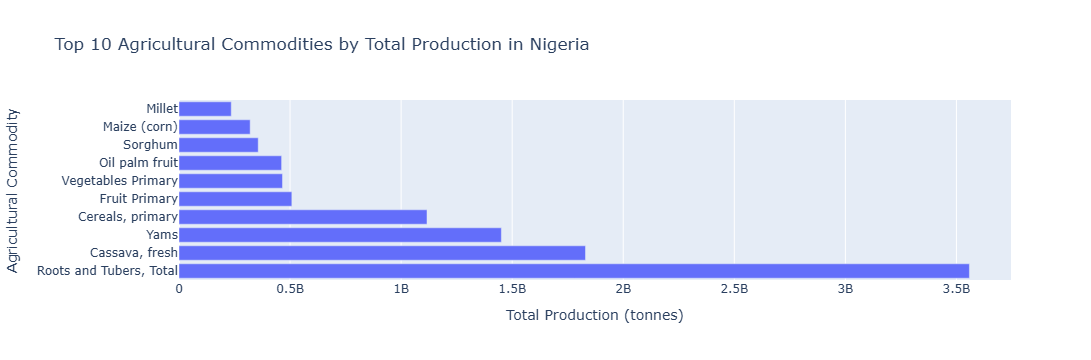

In [49]:
import plotly.express as px

fig = px.bar(
    top_production_df,
    x="Production",
    y="Item",
    orientation="h",
    title="Top 10 Agricultural Commodities by Total Production in Nigeria",
    labels={
        "Production": "Total Production (tonnes)",
        "Item": "Agricultural Commodity"
    }
)

fig.show()

In [50]:
 ### Why this chart matters
## It answers:
## Which agricultural commodities contributed the most production over the period covered by the dataset?

In [51]:
yearly_production = (
    crop_pivot
    .groupby("Year")["Production"]
    .sum()
    .reset_index()
)

yearly_production.head()

,Year,Production
0,1961,68473672.34
1,1962,70827172.25
2,1963,74176543.64
3,1964,75870395.70
4,1965,80173236.96


In [52]:
crop_pivot.columns

Index(['Area', 'Year', 'Item', 'Area_Harvested', 'Production', 'Yield'], dtype='str', name='Element')

In [53]:
crop_pivot["Production_per_Hectare"] = (
    crop_pivot["Production"] /
    crop_pivot["Area_Harvested"]
)

In [54]:
import numpy as np

median_production = crop_pivot["Production"].median()

crop_pivot["Production_Level"] = np.where(
    crop_pivot["Production"] >= median_production,
    "High Production",
    "Low Production"
)

In [55]:
crop_pivot["Period"] = np.where(
    crop_pivot["Year"] < 2000,
    "1961-1999",
    np.where(
        crop_pivot["Year"] < 2010,
        "2000-2009",
        np.where(
            crop_pivot["Year"] < 2020,
            "2010-2019",
            "2020-2024"
        )
    )
)

In [56]:
crop_pivot.columns

Index(['Area', 'Year', 'Item', 'Area_Harvested', 'Production', 'Yield',
       'Production_per_Hectare', 'Production_Level', 'Period'],
      dtype='str', name='Element')

In [57]:
crop_pivot["Period"].value_counts()

Period
1961-1999    3930
2010-2019    1042
2000-2009    1023
2020-2024     509
Name: count, dtype: int64

In [58]:
period_production = (
    crop_pivot
    .groupby("Period")["Production"]
    .sum()
    .reset_index()
)

period_production

,Period,Production
0,1961-1999,4.631840e+09
1,2000-2009,2.803801e+09
2,2010-2019,3.657520e+09
3,2020-2024,2.228904e+09


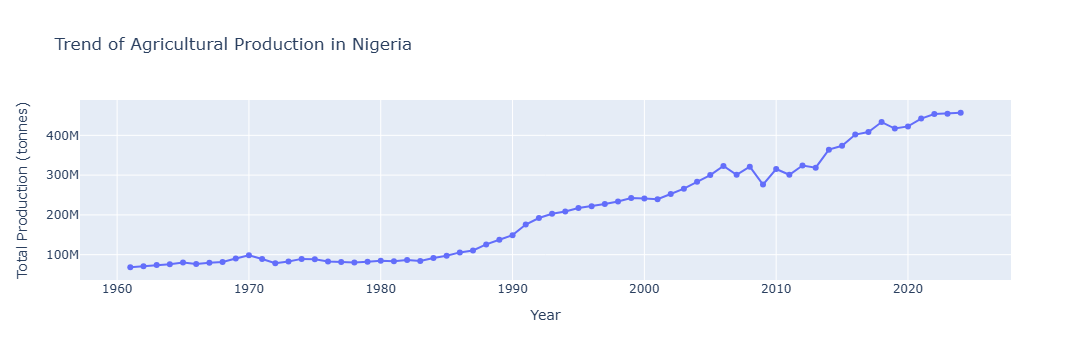

In [59]:
fig = px.line(
    yearly_production,
    x="Year",
    y="Production",
    markers=True,
    title="Trend of Agricultural Production in Nigeria",
    labels={
        "Year": "Year",
        "Production": "Total Production (tonnes)"
    }
)

fig.show()

In [60]:
period_production = (
    crop_pivot
    .groupby("Period")["Production"]
    .sum()
    .reset_index()
)

period_production

,Period,Production
0,1961-1999,4.631840e+09
1,2000-2009,2.803801e+09
2,2010-2019,3.657520e+09
3,2020-2024,2.228904e+09


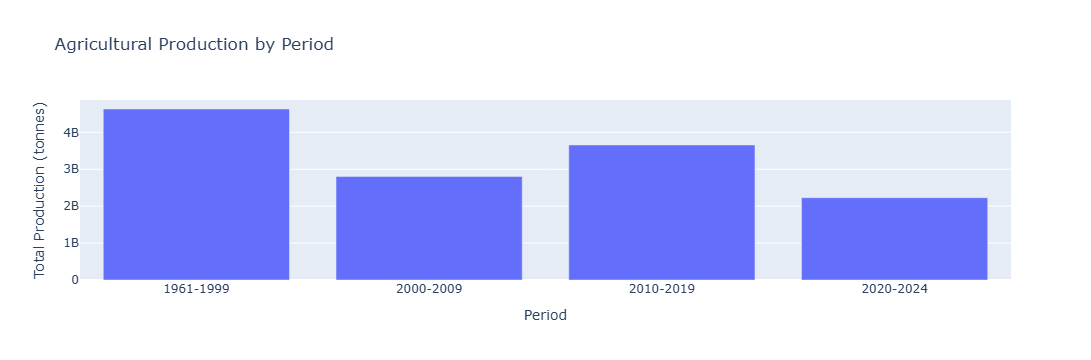

In [61]:
fig = px.bar(
    period_production,
    x="Period",
    y="Production",
    title="Agricultural Production by Period",
    labels={
        "Period": "Period",
        "Production": "Total Production (tonnes)"
    }
)

fig.show()

In [62]:
crop_pivot.to_csv(
    "Nigeria_Agricultural_Production_Final.csv",
    index=False
)

In [63]:
top_yield = (
    crop_pivot
    .groupby("Item")["Yield"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_yield

,Item,Yield
0,Sugar Crops Primary,29637.603125
1,Sugar cane,29637.603125
2,"Onions and shallots, green",14199.940625
3,Green garlic,13045.072222
4,"Cassava, fresh",9716.596875
5,Yams,9190.818750
6,"Roots and Tubers, Total",8824.003125
7,"Chillies and peppers, green (Capsicum spp. and...",8195.617188
8,Tomatoes,8114.201563
9,Carrots and turnips,8079.432813


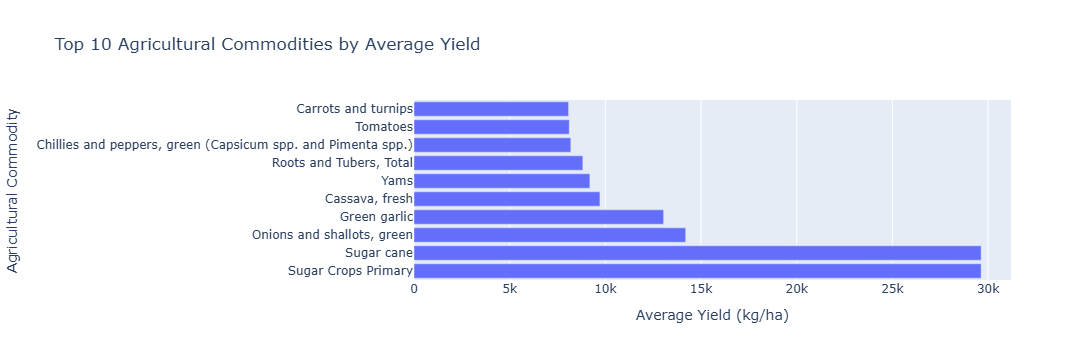

In [64]:
fig = px.bar(
    top_yield,
    x="Yield",
    y="Item",
    orientation="h",
    title="Top 10 Agricultural Commodities by Average Yield",
    labels={
        "Yield": "Average Yield (kg/ha)",
        "Item": "Agricultural Commodity"
    }
)

fig.show()

In [65]:
top_area = (
    crop_pivot
    .groupby("Item")["Area_Harvested"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_area

,Item,Area_Harvested
0,"Cereals, primary",901892000.0
1,"Roots and Tubers, Total",437473544.0
2,"Oilcrops, Oil Equivalent",422584598.0
3,"Oilcrops, Cake Equivalent",409839833.0
4,Sorghum,340533905.0
5,Millet,235235262.0
6,"Cassava, fresh",210056011.0
7,Maize (corn),209092910.0
8,"Pulses, Total",208731291.0
9,"Cow peas, dry",201295512.0


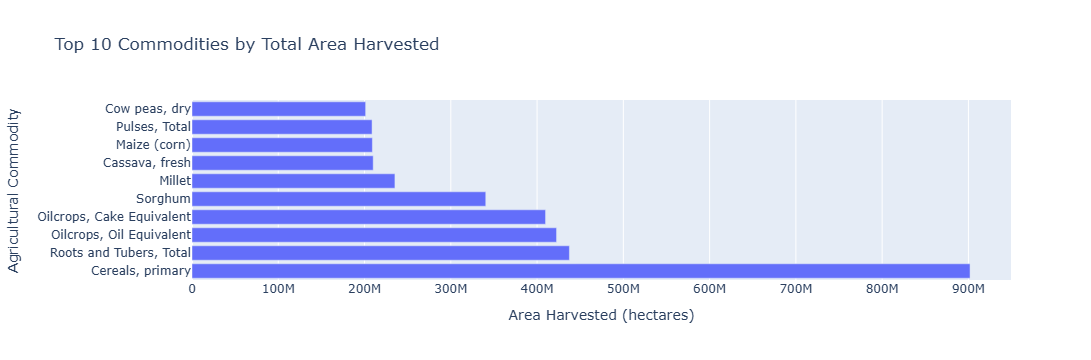

In [66]:
fig = px.bar(
    top_area,
    x="Area_Harvested",
    y="Item",
    orientation="h",
    title="Top 10 Commodities by Total Area Harvested",
    labels={
        "Area_Harvested": "Area Harvested (hectares)",
        "Item": "Agricultural Commodity"
    }
)

fig.show()

In [67]:
top_area = (
    crop_pivot
    .groupby("Item")["Area_Harvested"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_area

,Item,Area_Harvested
0,"Cereals, primary",901892000.0
1,"Roots and Tubers, Total",437473544.0
2,"Oilcrops, Oil Equivalent",422584598.0
3,"Oilcrops, Cake Equivalent",409839833.0
4,Sorghum,340533905.0
5,Millet,235235262.0
6,"Cassava, fresh",210056011.0
7,Maize (corn),209092910.0
8,"Pulses, Total",208731291.0
9,"Cow peas, dry",201295512.0


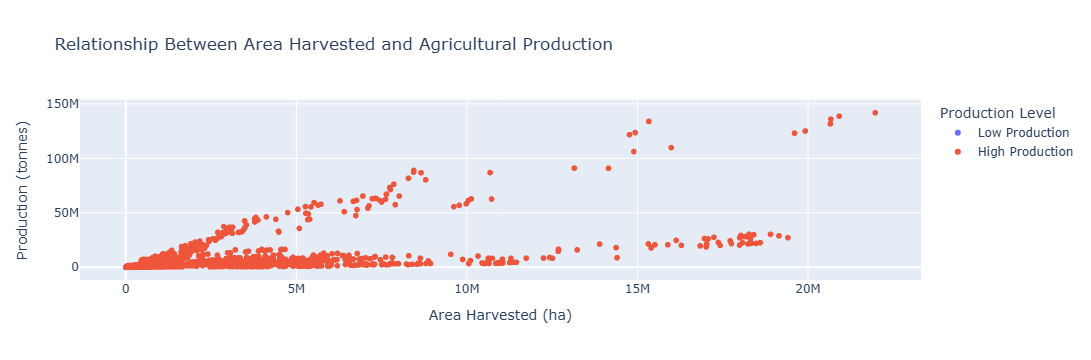

In [68]:
fig = px.scatter(
    crop_pivot,
    x="Area_Harvested",
    y="Production",
    color="Production_Level",
    hover_name="Item",
    title="Relationship Between Area Harvested and Agricultural Production",
    labels={
        "Area_Harvested": "Area Harvested (ha)",
        "Production": "Production (tonnes)",
        "Production_Level": "Production Level"
    }
)

fig.show()

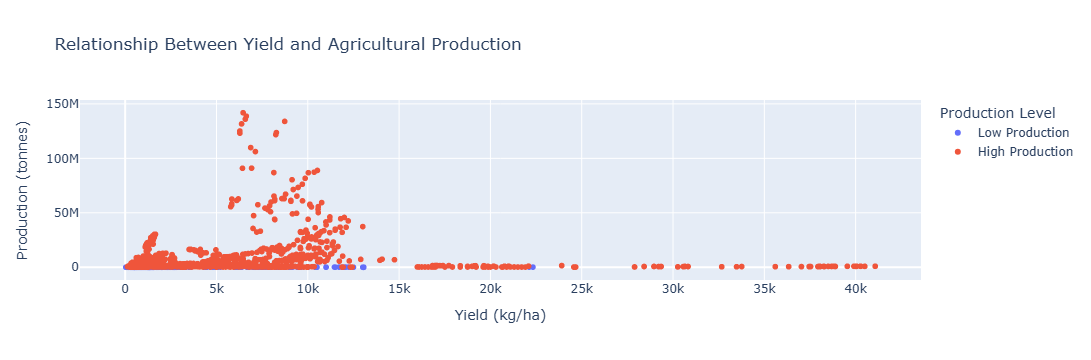

In [69]:
fig = px.scatter(
    crop_pivot,
    x="Yield",
    y="Production",
    color="Production_Level",
    hover_name="Item",
    title="Relationship Between Yield and Agricultural Production",
    labels={
        "Yield": "Yield (kg/ha)",
        "Production": "Production (tonnes)",
        "Production_Level": "Production Level"
    }
)

fig.show()

In [70]:
correlation = crop_pivot[
    [
        "Production",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare"
    ]
].corr()

correlation

Element,Production,Area_Harvested,Yield,Production_per_Hectare
Element,,,,
Production,1.000000,0.616137,0.106978,0.106987
Area_Harvested,0.616137,1.000000,-0.131739,-0.131724
Yield,0.106978,-0.131739,1.000000,0.999998
Production_per_Hectare,0.106987,-0.131724,0.999998,1.000000


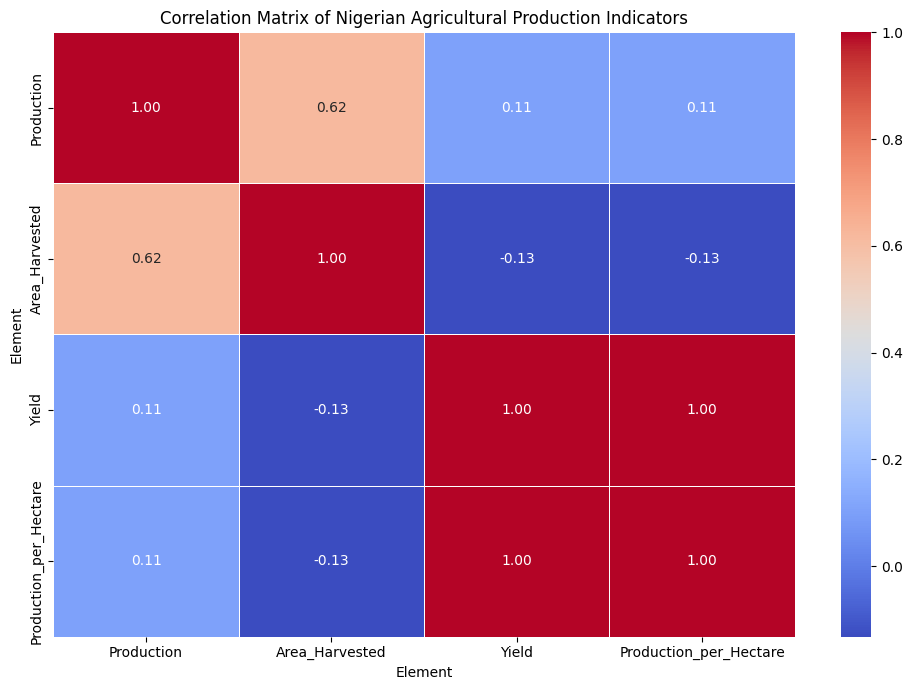

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Nigerian Agricultural Production Indicators"
)

plt.tight_layout()
plt.show()

In [72]:
crop_pivot.to_csv(
    "Nigeria_Agricultural_Production_Final.csv",
    index=False
)

print("Final dataset saved.")

Final dataset saved.


In [73]:
top_10_production = crop_pivot.sort_values(
    by="Production",
    ascending=False
).head(10)

top_10_production

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
6487,Nigeria,2024,"Roots and Tubers, Total",21968727.0,1.418724e+08,6457.9,6.457925,High Production,2020-2024
6399,Nigeria,2023,"Roots and Tubers, Total",20912910.0,1.387151e+08,6633.0,6.632988,High Production,2020-2024
6293,Nigeria,2022,"Roots and Tubers, Total",20667849.0,1.359859e+08,6579.6,6.579586,High Production,2020-2024
5870,Nigeria,2018,"Roots and Tubers, Total",15333631.0,1.339265e+08,8734.2,8.734165,High Production,2010-2019
6187,Nigeria,2021,"Roots and Tubers, Total",20651983.0,1.316394e+08,6374.2,6.374178,High Production,2020-2024
6081,Nigeria,2020,"Roots and Tubers, Total",19917167.0,1.250891e+08,6280.5,6.280464,High Production,2020-2024
5765,Nigeria,2017,"Roots and Tubers, Total",14931189.0,1.236412e+08,8280.7,8.280731,High Production,2010-2019
5975,Nigeria,2019,"Roots and Tubers, Total",19603589.0,1.231383e+08,6281.4,6.281416,High Production,2010-2019
5660,Nigeria,2016,"Roots and Tubers, Total",14765892.0,1.217767e+08,8247.2,8.247160,High Production,2010-2019
5555,Nigeria,2015,"Roots and Tubers, Total",15988592.0,1.098833e+08,6872.6,6.872609,High Production,2010-2019


In [74]:
bottom_10_production = crop_pivot.sort_values(
    by="Production",
    ascending=True
).head(10)

bottom_10_production

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
556,Nigeria,1966,Oil of sesame seed,NaN,0.0,NaN,NaN,Low Production,1961-1999
839,Nigeria,1969,"Kenaf, and other textile bast fibres, raw or r...",0.0,0.0,NaN,NaN,Low Production,1961-1999
420,Nigeria,1965,Cottonseed oil,NaN,0.0,NaN,NaN,Low Production,1961-1999
88,Nigeria,1961,Soya bean oil,NaN,0.0,NaN,NaN,Low Production,1961-1999
464,Nigeria,1965,"Other oil seeds, n.e.c.",NaN,0.0,NaN,NaN,Low Production,1961-1999
456,Nigeria,1965,Oil of sesame seed,NaN,0.0,NaN,NaN,Low Production,1961-1999
453,Nigeria,1965,Molasses,NaN,0.0,NaN,NaN,Low Production,1961-1999
1139,Nigeria,1972,"Kenaf, and other textile bast fibres, raw or r...",0.0,0.0,NaN,NaN,Low Production,1961-1999
2288,Nigeria,1983,Soya bean oil,NaN,0.0,NaN,NaN,Low Production,1961-1999
364,Nigeria,1964,"Other oil seeds, n.e.c.",NaN,0.0,NaN,NaN,Low Production,1961-1999


In [75]:
top_10_yield = crop_pivot.sort_values(
    by="Yield",
    ascending=False
).head(10)

top_10_yield

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
2999,Nigeria,1990,Sugar Crops Primary,22400.0,920000.0,41071.4,41.071429,High Production,1961-1999
3000,Nigeria,1990,Sugar cane,22400.0,920000.0,41071.4,41.071429,High Production,1961-1999
2291,Nigeria,1983,Sugar cane,20000.0,810000.0,40500.0,40.500000,High Production,1961-1999
2290,Nigeria,1983,Sugar Crops Primary,20000.0,810000.0,40500.0,40.500000,High Production,1961-1999
2491,Nigeria,1985,Sugar Crops Primary,21400.0,862000.0,40280.4,40.280374,High Production,1961-1999
2492,Nigeria,1985,Sugar cane,21400.0,862000.0,40280.4,40.280374,High Production,1961-1999
2090,Nigeria,1981,Sugar Crops Primary,23000.0,926000.0,40260.9,40.260870,High Production,1961-1999
2091,Nigeria,1981,Sugar cane,23000.0,926000.0,40260.9,40.260870,High Production,1961-1999
2390,Nigeria,1984,Sugar Crops Primary,20500.0,821000.0,40048.8,40.048780,High Production,1961-1999
2391,Nigeria,1984,Sugar cane,20500.0,821000.0,40048.8,40.048780,High Production,1961-1999


In [76]:
recent_data = crop_pivot[
    crop_pivot["Year"] >= 2020
]

recent_data.head(10)

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
5995,Nigeria,2020,Bananas,476070.0,5583830.00,11729.0,11.729010,High Production,2020-2024
5996,Nigeria,2020,"Beef and Buffalo Meat, primary",NaN,325427.88,NaN,NaN,High Production,2020-2024
5997,Nigeria,2020,"Beer of barley, malted",NaN,1880000.00,NaN,NaN,High Production,2020-2024
5998,Nigeria,2020,Butter and Ghee,NaN,11933.41,NaN,NaN,Low Production,2020-2024
5999,Nigeria,2020,Butter of cow milk,NaN,11933.41,NaN,NaN,Low Production,2020-2024
6000,Nigeria,2020,"Buttermilk, dry",NaN,2353.78,NaN,NaN,Low Production,2020-2024
6001,Nigeria,2020,Carrots and turnips,26787.0,237485.15,8865.7,8.865687,High Production,2020-2024
6002,Nigeria,2020,"Cashew nuts, in shell",167570.0,91914.82,548.5,0.548516,Low Production,2020-2024
6003,Nigeria,2020,"Cassava, fresh",9614230.0,55565610.00,5779.5,5.779517,High Production,2020-2024
6004,Nigeria,2020,"Cattle fat, unrendered",NaN,9297.94,NaN,NaN,Low Production,2020-2024


In [77]:
high_production = crop_pivot[
    crop_pivot["Production_Level"] == "High Production"
]

high_production.head(10)

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
6,Nigeria,1961,"Cassava, fresh",780000.0,7384000.0,9466.7,9.466667,High Production,1961-1999
8,Nigeria,1961,"Cereals, primary",10621000.0,7891000.0,743.0,0.742962,High Production,1961-1999
12,Nigeria,1961,"Chillies and peppers, green (Capsicum spp. and...",48500.0,388000.0,8000.0,8.000000,High Production,1961-1999
13,Nigeria,1961,"Citrus Fruit, Total",300000.0,1000000.0,3333.3,3.333333,High Production,1961-1999
14,Nigeria,1961,Cocoa beans,700000.0,197000.0,281.4,0.281429,High Production,1961-1999
21,Nigeria,1961,"Cow peas, dry",1216000.0,431000.0,354.4,0.354441,High Production,1961-1999
30,Nigeria,1961,Fruit Primary,753000.0,3338000.0,4432.9,4.432935,High Production,1961-1999
34,Nigeria,1961,Green corn (maize),138000.0,277000.0,2007.2,2.007246,High Production,1961-1999
36,Nigeria,1961,"Groundnuts, excluding shelled",1488000.0,1565000.0,1051.7,1.051747,High Production,1961-1999
41,Nigeria,1961,Maize (corn),1375000.0,1107000.0,805.1,0.805091,High Production,1961-1999


In [78]:
crop_pivot.iloc[0]

Element
Area                                             Nigeria
Year                                                1961
Item                      Beef and Buffalo Meat, primary
Area_Harvested                                       NaN
Production                                      156300.0
Yield                                                NaN
Production_per_Hectare                               NaN
Production_Level                          Low Production
Period                                         1961-1999
Name: 0, dtype: object

In [79]:
crop_pivot.iloc[0:10]

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
0,Nigeria,1961,"Beef and Buffalo Meat, primary",NaN,156300.00,NaN,NaN,Low Production,1961-1999
1,Nigeria,1961,"Beer of barley, malted",NaN,25000.00,NaN,NaN,Low Production,1961-1999
2,Nigeria,1961,Butter and Ghee,NaN,3242.99,NaN,NaN,Low Production,1961-1999
3,Nigeria,1961,Butter of cow milk,NaN,3242.99,NaN,NaN,Low Production,1961-1999
4,Nigeria,1961,Carrots and turnips,20000.0,150000.00,7500.0,7.500000,Low Production,1961-1999
5,Nigeria,1961,"Cashew nuts, in shell",15000.0,7000.00,466.7,0.466667,Low Production,1961-1999
6,Nigeria,1961,"Cassava, fresh",780000.0,7384000.00,9466.7,9.466667,High Production,1961-1999
7,Nigeria,1961,"Cattle fat, unrendered",NaN,4465.71,NaN,NaN,Low Production,1961-1999
8,Nigeria,1961,"Cereals, primary",10621000.0,7891000.00,743.0,0.742962,High Production,1961-1999
9,Nigeria,1961,Cheese (All Kinds),NaN,2593.75,NaN,NaN,Low Production,1961-1999


In [80]:
crop_pivot.iloc[10:20]

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
10,Nigeria,1961,Cheese from skimmed cow milk,NaN,2593.75,NaN,NaN,Low Production,1961-1999
11,Nigeria,1961,"Chillies and peppers, dry (Capsicum spp., Pime...",20000.0,30000.00,1500.0,1.500000,Low Production,1961-1999
12,Nigeria,1961,"Chillies and peppers, green (Capsicum spp. and...",48500.0,388000.00,8000.0,8.000000,High Production,1961-1999
13,Nigeria,1961,"Citrus Fruit, Total",300000.0,1000000.00,3333.3,3.333333,High Production,1961-1999
14,Nigeria,1961,Cocoa beans,700000.0,197000.00,281.4,0.281429,High Production,1961-1999
15,Nigeria,1961,Coconut oil,NaN,2714.50,NaN,NaN,Low Production,1961-1999
16,Nigeria,1961,"Coconuts, in shell",28000.0,76000.00,2714.3,2.714286,Low Production,1961-1999
17,Nigeria,1961,"Coffee, green",6000.0,1100.00,183.3,0.183333,Low Production,1961-1999
18,Nigeria,1961,"Cotton lint, ginned",NaN,51000.00,NaN,NaN,Low Production,1961-1999
19,Nigeria,1961,Cotton seed,NaN,102000.00,NaN,NaN,Low Production,1961-1999


In [81]:
crop_pivot.iloc[:, 0:5]

Element,Area,Year,Item,Area_Harvested,Production
0,Nigeria,1961,"Beef and Buffalo Meat, primary",NaN,156300.00
1,Nigeria,1961,"Beer of barley, malted",NaN,25000.00
2,Nigeria,1961,Butter and Ghee,NaN,3242.99
3,Nigeria,1961,Butter of cow milk,NaN,3242.99
4,Nigeria,1961,Carrots and turnips,20000.0,150000.00
...,...,...,...,...,...
6499,Nigeria,2024,"Treenuts, Total",172997.0,88405.97
6500,Nigeria,2024,Unmanufactured tobacco,9525.0,5577.52
6501,Nigeria,2024,Vegetables Primary,4667114.0,16330611.28
6502,Nigeria,2024,Wheat,27906.0,43926.98


In [82]:
crop_pivot.iloc[0:10, 0:5]

Element,Area,Year,Item,Area_Harvested,Production
0,Nigeria,1961,"Beef and Buffalo Meat, primary",NaN,156300.00
1,Nigeria,1961,"Beer of barley, malted",NaN,25000.00
2,Nigeria,1961,Butter and Ghee,NaN,3242.99
3,Nigeria,1961,Butter of cow milk,NaN,3242.99
4,Nigeria,1961,Carrots and turnips,20000.0,150000.00
5,Nigeria,1961,"Cashew nuts, in shell",15000.0,7000.00
6,Nigeria,1961,"Cassava, fresh",780000.0,7384000.00
7,Nigeria,1961,"Cattle fat, unrendered",NaN,4465.71
8,Nigeria,1961,"Cereals, primary",10621000.0,7891000.00
9,Nigeria,1961,Cheese (All Kinds),NaN,2593.75


In [83]:
crop_pivot.iloc[-10:]

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
6494,Nigeria,2024,Sugar Crops Primary,88518.0,1509132.57,17048.9,17.048878,High Production,2020-2024
6495,Nigeria,2024,Sugar cane,88518.0,1509132.57,17048.9,17.048878,High Production,2020-2024
6496,Nigeria,2024,Sweet potatoes,1509659.0,4091239.04,2710.0,2.710042,High Production,2020-2024
6497,Nigeria,2024,Taro,1393692.0,8605587.30,6174.7,6.174669,High Production,2020-2024
6498,Nigeria,2024,Tomatoes,822140.0,3726166.42,4532.3,4.532277,High Production,2020-2024
6499,Nigeria,2024,"Treenuts, Total",172997.0,88405.97,511.0,0.511026,Low Production,2020-2024
6500,Nigeria,2024,Unmanufactured tobacco,9525.0,5577.52,585.6,0.585566,Low Production,2020-2024
6501,Nigeria,2024,Vegetables Primary,4667114.0,16330611.28,3499.1,3.499081,High Production,2020-2024
6502,Nigeria,2024,Wheat,27906.0,43926.98,1574.1,1.574105,Low Production,2020-2024
6503,Nigeria,2024,Yams,8015649.0,65322031.57,8149.3,8.149313,High Production,2020-2024


In [84]:
crop_pivot.iloc[::2]

Element,Area,Year,Item,Area_Harvested,Production,Yield,Production_per_Hectare,Production_Level,Period
0,Nigeria,1961,"Beef and Buffalo Meat, primary",NaN,156300.00,NaN,NaN,Low Production,1961-1999
2,Nigeria,1961,Butter and Ghee,NaN,3242.99,NaN,NaN,Low Production,1961-1999
4,Nigeria,1961,Carrots and turnips,20000.0,150000.00,7500.0,7.500000,Low Production,1961-1999
6,Nigeria,1961,"Cassava, fresh",780000.0,7384000.00,9466.7,9.466667,High Production,1961-1999
8,Nigeria,1961,"Cereals, primary",10621000.0,7891000.00,743.0,0.742962,High Production,1961-1999
...,...,...,...,...,...,...,...,...,...
6494,Nigeria,2024,Sugar Crops Primary,88518.0,1509132.57,17048.9,17.048878,High Production,2020-2024
6496,Nigeria,2024,Sweet potatoes,1509659.0,4091239.04,2710.0,2.710042,High Production,2020-2024
6498,Nigeria,2024,Tomatoes,822140.0,3726166.42,4532.3,4.532277,High Production,2020-2024
6500,Nigeria,2024,Unmanufactured tobacco,9525.0,5577.52,585.6,0.585566,Low Production,2020-2024


In [85]:
descriptive_stats = crop_pivot[
    [
        "Production",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare"
    ]
].describe().T

descriptive_stats

,count,mean,std,min,25%,50%,75%,max
Element,,,,,,,,
Production,6504.0,2.048288e+06,8.392910e+06,0.000000,25000.000000,172000.000000,8.064260e+05,1.418724e+08
Area_Harvested,3713.0,1.324424e+06,2.740686e+06,0.000000,40000.000000,209100.000000,1.100000e+06,2.196873e+07
Yield,3693.0,4.290957e+03,6.167128e+03,34.200000,648.700000,1848.300000,6.229500e+03,4.107140e+04
Production_per_Hectare,3693.0,4.290776e+00,6.167177e+00,0.034212,0.648654,1.848287,6.229462e+00,4.107143e+01


In [86]:
descriptive_stats["median"] = crop_pivot[
    [
        "Production",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare"
    ]
].median()

descriptive_stats

,count,mean,std,min,25%,50%,75%,max,median
Element,,,,,,,,,
Production,6504.0,2.048288e+06,8.392910e+06,0.000000,25000.000000,172000.000000,8.064260e+05,1.418724e+08,172000.000000
Area_Harvested,3713.0,1.324424e+06,2.740686e+06,0.000000,40000.000000,209100.000000,1.100000e+06,2.196873e+07,209100.000000
Yield,3693.0,4.290957e+03,6.167128e+03,34.200000,648.700000,1848.300000,6.229500e+03,4.107140e+04,1848.300000
Production_per_Hectare,3693.0,4.290776e+00,6.167177e+00,0.034212,0.648654,1.848287,6.229462e+00,4.107143e+01,1.848287


In [87]:
crop_pivot.to_csv(
    "Nigeria_Agricultural_Production_Final.csv",
    index=False
)

print("Dataset saved successfully.")

Dataset saved successfully.


In [88]:
crop_pivot["High_Production"] = (
    crop_pivot["Production_Level"] == "High Production"
).astype(int)

crop_pivot["High_Production"].value_counts()

High_Production
1    3255
0    3249
Name: count, dtype: int64

In [89]:
X = crop_pivot[
    [
        "Year",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare"
    ]
]

y = crop_pivot["High_Production"]

In [90]:
X.head()

Element,Year,Area_Harvested,Yield,Production_per_Hectare
0,1961,NaN,NaN,NaN
1,1961,NaN,NaN,NaN
2,1961,NaN,NaN,NaN
3,1961,NaN,NaN,NaN
4,1961,20000.0,7500.0,7.5


In [91]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: High_Production, dtype: int64

In [92]:
import numpy as np

print("Missing values:")
print(X.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X).sum())

Missing values:
Element
Year                         0
Area_Harvested            2791
Yield                     2811
Production_per_Hectare    2811
dtype: int64

Infinite values:
Element
Year                      0
Area_Harvested            0
Yield                     0
Production_per_Hectare    0
dtype: int64


In [93]:
print(X.shape)
print(y.shape)

(6504, 4)
(6504,)


In [94]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [95]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5203, 4)
Testing data: (1301, 4)


In [96]:
### Why stratify=y?
## It helps maintain the proportion of High/Low Production observations in both the training and testing datasets.

In [97]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [98]:
X.isnull().sum()

Element
Year                         0
Area_Harvested            2791
Yield                     2811
Production_per_Hectare    2811
dtype: int64

In [99]:
print("Rows in X:", len(X))
print("Rows in y:", len(y))

Rows in X: 6504
Rows in y: 6504


In [100]:
import numpy as np

print("Missing values:")
print(X.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X).sum())

Missing values:
Element
Year                         0
Area_Harvested            2791
Yield                     2811
Production_per_Hectare    2811
dtype: int64

Infinite values:
Element
Year                      0
Area_Harvested            0
Yield                     0
Production_per_Hectare    0
dtype: int64


In [101]:
model_data = crop_pivot[
    [
        "Year",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare",
        "High_Production"
    ]
].copy()

In [102]:
model_data = model_data.replace(
    [np.inf, -np.inf],
    np.nan
)

In [103]:
model_data = model_data.dropna()

In [104]:
print("Original rows:", len(crop_pivot))
print("Rows available for modelling:", len(model_data))

Original rows: 6504
Rows available for modelling: 3693


In [105]:
model_data.isnull().sum()

Element
Year                      0
Area_Harvested            0
Yield                     0
Production_per_Hectare    0
High_Production           0
dtype: int64

In [106]:
X = model_data[
    [
        "Year",
        "Area_Harvested",
        "Yield",
        "Production_per_Hectare"
    ]
]

y = model_data["High_Production"]

In [107]:
print(X.shape)
print(y.shape)

(3693, 4)
(3693,)


In [108]:
X.isnull().sum()

Element
Year                      0
Area_Harvested            0
Yield                     0
Production_per_Hectare    0
dtype: int64

In [109]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [110]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [111]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [112]:
y_pred = logistic_model.predict(X_test_scaled)

In [113]:
y_pred[:20]

array([0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1])

In [114]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Model Accuracy: {accuracy:.2%}")

Model Accuracy: 87.82%


In [115]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Low Production",
            "High Production"
        ]
    )
)

                 precision    recall  f1-score   support

 Low Production       0.81      0.85      0.83       253
High Production       0.92      0.90      0.91       486

       accuracy                           0.88       739
      macro avg       0.86      0.87      0.87       739
   weighted avg       0.88      0.88      0.88       739



In [116]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[214  39]
 [ 51 435]]


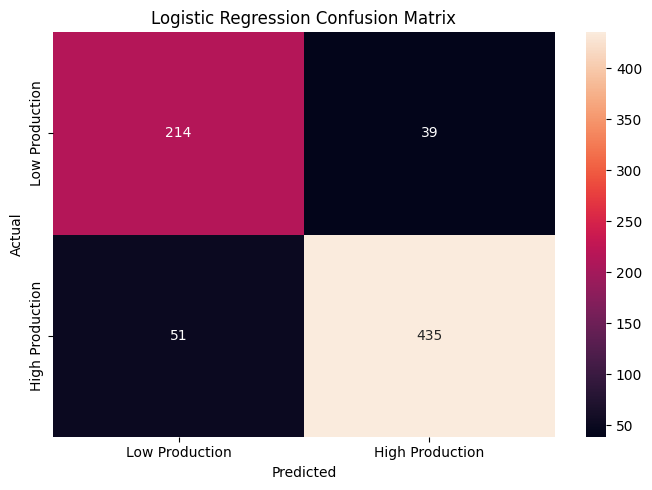

In [117]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Low Production",
        "High Production"
    ],
    yticklabels=[
        "Low Production",
        "High Production"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

In [118]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients

,Feature,Coefficient
0,Year,0.253790
1,Area_Harvested,13.702859
2,Yield,1.369524
3,Production_per_Hectare,1.379752


In [119]:
coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
1,Area_Harvested,13.702859
3,Production_per_Hectare,1.379752
2,Yield,1.369524
0,Year,0.253790


In [120]:
### Interpretation
## Because we standardized the predictors, the coefficients are on a comparable standardized scale.
## Positive coefficient → associated with higher log-odds of being classified as High Production.
## Negative coefficient → associated with lower log-odds of being classified as High Production.
## A coefficient is not evidence of causation.

In [121]:
### predicted probabilities

In [122]:
y_probability = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [123]:
y_probability[:20]

array([0.46449741, 0.32619106, 0.99999996, 0.09411429, 0.96256879,
       0.99999715, 1.        , 0.13597925, 0.77202844, 1.        ,
       1.        , 0.15933457, 0.99999984, 0.98778533, 0.11812471,
       0.6107941 , 1.        , 0.87138538, 0.86264992, 0.93336309])

In [124]:
prediction_results = X_test.copy()

prediction_results["Actual"] = y_test.values
prediction_results["Predicted"] = y_pred
prediction_results["Probability_High_Production"] = y_probability

prediction_results.head(10)

Element,Year,Area_Harvested,Yield,Production_per_Hectare,Actual,Predicted,Probability_High_Production
3947,2000,36000.0,4444.4,4.444444,0,0,0.464497
2334,1984,105000.0,2857.1,2.857143,1,0,0.326191
5548,2015,3779111.0,627.5,0.627458,1,1,1.000000
2518,1986,2400.0,500.0,0.500000,0,0,0.094114
3592,1996,580000.0,6044.8,6.044828,1,1,0.962569
3410,1994,18750.0,33760.0,33.760000,1,1,0.999997
3401,1994,5265900.0,10573.9,10.573881,1,1,1.000000
1683,1977,128000.0,296.9,0.296875,0,0,0.135979
5488,2015,36384.0,7027.8,7.027814,1,1,0.772028
4141,2002,3446000.0,9901.3,9.901335,1,1,1.000000


In [125]:
prediction_results.to_csv(
    "FAOSTAT_Logistic_Regression_Predictions.csv",
    index=False
)

print("Prediction results saved successfully.")

Prediction results saved successfully.


In [126]:
crop_pivot.to_csv(
    "Nigeria_Agricultural_Production_Final.csv",
    index=False
)

In [127]:
prediction_results.to_csv(
    "FAOSTAT_Logistic_Regression_Predictions.csv",
    index=False
)

In [128]:
### CONCLUSION
## The analysis of Nigeria's agricultural production data provided insights into production, harvested area and yield across agricultural commodities 
## and years. Exploratory data analysis revealed differences in production levels and productivity among commodities, while the correlation analysis 
## examined relationships among production, harvested area, yield and production per hectare.

## The analysis also used descriptive statistics, sorting and filtering operations, index-based selection and interactive visualizations to explore 
## the dataset. A logistic regression model was subsequently developed to classify observations into high- and low-production categories using 
## selected agricultural indicators as predictors.

## The model evaluation was based on the test dataset using accuracy, classification metrics and a confusion matrix. The results demonstrate how 
## Python-based data analysis and machine-learning techniques can be applied to agricultural production data to support evidence-based analysis.

In [129]:
### Linear Regression
## Linear regression is a supervised machine-learning/statistical technique used to model the relationship between a continuous dependent variable and
## one or more independent variables.

In [130]:
### Logistic Regression
## Logistic regression is a supervised classification technique used when the dependent variable represents a categorical outcome, particularly a 
## binary outcome such as 0/1.

## It estimates the probability that an observation belongs to a particular class.